# Dubai Property Price Estimator

### Context

The project aims to estimate the fair **asking price** of properties listed in Dubai. Each listing has features such as location, bedrooms, bathrooms, and property type, and a target **price**, that the model learns to predict. Sellers can use the estimated price to check whether a listing is **underpriced** or **overpriced**.

### Content of Dataset

Column 1 : **Title** represents the headline of the advertisement for this property   
Column 2 : **displayAddress** represents the location of the listing **(key feature since some locations are prime thus higher price)**  
Column 3 : **bathrooms** represents the number of bathrooms in the property **(key feature since more bathrooms means higher price )**  
Column 4 : **bedrooms** represents the number of bedrooms in the property **(key feature since more bedrooms means higher price)**  
Column 5 : **addOn** represents the date the listing was posted  
Column 6 : **type** represents the type of listing (residential or commercial)  
Column 7 : **price** represents the asking price of the property in **AED** **(Target)**  
Column 8 : **verified** represents whether the listing was verified by the portal  
Column 9 : **priceDuration** represents the time period the price covers (eg rental listings show monthly or yearly, since the data only contains properties being sold, it contains 'sell' only)  
Column 10 : **sizeMin** represents the size of the property in **square feet** **(Key feature since bigger properties mean bigger price)**  
Column 11 : **furnishing** represents whether the property is furnished, not furnished, or partly furnished



### Project Goals:

As a **supervised** regression problem, the goal of the project is:  
- Predict the asking price of UAE residential properties for sale from location, size, bedrooms, bathrooms, and furnishing.
- Explore the data to understand what drives price.
- Compare regression models and select the best one.
- Deploy the model as a web service with Docker so sellers can check whether a price is fair.


### Data Preperation:

Dataset from https://www.kaggle.com/datasets/kanchana1990/uae-real-estate-2024-dataset/data 

#### Understanding the Data

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Data/uae_real_estate_2024.csv')

In [3]:
df.head()

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,Residential for Sale,2500000,True,sell,1323 sqft,NO,MNA Properties is delighted to offer this apar...
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,Residential for Sale,7200000,True,sell,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R..."
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,Residential for Sale,3600000,True,sell,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,Residential for Sale,2999999,True,sell,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,Residential for Sale,2449999,True,sell,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...


In [4]:
print(f'The dataset has {df.shape[0]} rows and {df.shape[1]} columns')

The dataset has 5058 rows and 12 columns


In [5]:
df.sample(5) #Picks randomly 5 rows (more data can be seen )

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description
4907,2026 Handover | Near Metro | 2 BR | 40/60 Plan,"Enqlave, Al Furjan, Dubai",3,2,2024-07-08T08:23:43Z,Residential for Sale,1425000,False,sell,1160 sqft,NO,"Discover Luxury Living at Enclave by Aqasa, Di..."
4996,Luxury Apartment | Flexible PP | Ready Q3 2025,"V1ter Residence, Jumeirah Village Circle, Dubai",3,2,2024-06-25T09:03:07Z,Residential for Sale,1448817,False,sell,1036 sqft,YES,<p>Springfield Real Estate offers you V1ter To...
743,Huge Layout | Genuine Resale | Urgent Deal,"DAMAC Casa, Dubai Media City, Dubai",2,1,2024-08-08T08:26:29Z,Residential for Sale,2950000,True,sell,946 sqft,NO,"Brought to you by Driven Properties, this 1 Be..."
2656,High Floor |Balcony+Greenery View |Waterfront ...,"Sobha Hartland Waves, Sobha Hartland, Mohammed...",2,2,2024-06-20T14:10:05Z,Residential for Sale,2000000,True,sell,850 sqft,NO,Waves at the Waterfront District is an impress...
2965,Prime Location | High ROI | Rented,"Joya Blanca Residences, Arjan, Dubai",2,1,2024-07-03T07:42:47Z,Residential for Sale,925000,True,sell,683 sqft,NO,Savoy Properties offers you this amazing 1BHK ...


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   title           5058 non-null   str  
 1   displayAddress  5058 non-null   str  
 2   bathrooms       4938 non-null   str  
 3   bedrooms        4935 non-null   str  
 4   addedOn         5058 non-null   str  
 5   type            5058 non-null   str  
 6   price           5058 non-null   int64
 7   verified        5058 non-null   bool 
 8   priceDuration   5058 non-null   str  
 9   sizeMin         5058 non-null   str  
 10  furnishing      5056 non-null   str  
 11  description     5057 non-null   str  
dtypes: bool(1), int64(1), str(10)
memory usage: 439.7 KB


In [7]:
df.dtypes[df.dtypes == 'str'].index # finds all columns that are strings 

Index(['title', 'displayAddress', 'bathrooms', 'bedrooms', 'addedOn', 'type',
       'priceDuration', 'sizeMin', 'furnishing', 'description'],
      dtype='str')

We will need to clean the data since most numerical features are strings therefore we will have to change them back

In [8]:
df.dtypes

title               str
displayAddress      str
bathrooms           str
bedrooms            str
addedOn             str
type                str
price             int64
verified           bool
priceDuration       str
sizeMin             str
furnishing          str
description         str
dtype: object

In [9]:
df.isna().sum() #Since the values that are missing less than 50% for all the column we can fill them rather than removing them  

title               0
displayAddress      0
bathrooms         120
bedrooms          123
addedOn             0
type                0
price               0
verified            0
priceDuration       0
sizeMin             0
furnishing          2
description         1
dtype: int64

In [10]:
df.describe()

,price
count,5.058000e+03
mean,5.050924e+06
std,1.000928e+07
min,1.000000e+05
25%,1.200000e+06
50%,2.350000e+06
75%,4.499375e+06
max,1.990000e+08


Are there any duplicate observations?

In [11]:
df.duplicated(keep ='first').sum() 

np.int64(0)

There are 0 duplicated columns in the dataset 

### Drop features priceDuration and type 

Since the features priceDuration and type are always the same having them won't impact the model.The feature type is always 'residential for sale' and the priceDuration is always 'year' thus they are not impacting price 

In [12]:
df['priceDuration'].unique(), df['type'].unique()

(<StringArray>
 ['sell']
 Length: 1, dtype: str,
 <StringArray>
 ['Residential for Sale']
 Length: 1, dtype: str)

In [13]:
df = df.drop(['priceDuration','type'], axis = 1)

In [14]:
df 

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,sizeMin,furnishing,description
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,2500000,True,1323 sqft,NO,MNA Properties is delighted to offer this apar...
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,7200000,True,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R..."
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,3600000,True,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,2999999,True,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,2449999,True,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...
...,...,...,...,...,...,...,...,...,...,...
5053,07 Layout | Handover Q2 2025 | Multiple Units ...,"Sobha Creek Vistas Grande, Sobha Hartland, Moh...",3,2,2024-07-10T14:07:57Z,2345000,True,1268 sqft,PARTLY,Nobel Victory Real Estate are proud to present...
5054,Emaar | Waterfront Apartment | 10% DP | 5-Yr PP,"Al Marjan Island, Ras Al Khaimah",2,1,2024-08-12T13:08:33Z,3007888,False,854 sqft,NO,"Discover Address Residence by Emaar, nestled o..."
5055,Upgraded | Spacious With Private Garden,"Oia Residence, Motor City, Dubai",5,4,2024-04-20T08:43:16Z,4000000,True,3813 sqft,NO,Rocky Real Estate presents an Exclusive and up...
5056,"10 Series | Full Sea, Burj Khalifa View Exclusive","The Grand, Dubai Creek Harbour (The Lagoons), ...",2,2,2024-07-08T07:05:56Z,3800000,True,1300 sqft,NO,Dingstone Real Estate is pleased to present to...


#### Data cleaning and Feature Engineering

In [15]:
df['sizeMin'].head()

0    1323 sqft
1    1410 sqft
2    2324 sqft
3    1647 sqft
4    2105 sqft
Name: sizeMin, dtype: str

In [16]:
df['size_sqft'] = df['sizeMin'].str.replace('sqft','').str.strip() 

In [17]:
df['size_sqft'] = df['size_sqft'].astype('float64')

In [18]:
df['size_sqft']

0       1323.0
1       1410.0
2       2324.0
3       1647.0
4       2105.0
         ...  
5053    1268.0
5054     854.0
5055    3813.0
5056    1300.0
5057    3685.0
Name: size_sqft, Length: 5058, dtype: float64

In [19]:
df.head()

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,sizeMin,furnishing,description,size_sqft
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,2500000,True,1323 sqft,NO,MNA Properties is delighted to offer this apar...,1323.0
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,7200000,True,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R...",1410.0
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,3600000,True,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...,2324.0
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,2999999,True,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...,1647.0
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,2449999,True,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...,2105.0


In [20]:
df['bathrooms'].value_counts()

bathrooms
2       1209
1       1038
3        902
4        686
5        511
6        273
7        206
7+       112
none       1
Name: count, dtype: int64

In [21]:
df['bathrooms'] = df['bathrooms'].replace({'7+':'7','none': np.nan})

In [22]:
df['bathrooms'].value_counts()

bathrooms
2    1209
1    1038
3     902
4     686
5     511
7     318
6     273
Name: count, dtype: int64

In [23]:
df['bathrooms'] = df['bathrooms'].astype('float64')

In [24]:
df['bathrooms'].value_counts(dropna = False)

bathrooms
2.0    1209
1.0    1038
3.0     902
4.0     686
5.0     511
7.0     318
6.0     273
NaN     121
Name: count, dtype: int64

Bathroom feature cleanup:
It was stored as text in the data and contained two non numerical values ( **'7+'** and **'none'**)  

- **7+** (112 listings): replaced with **7**. This treats "7 or more" as 7, a small simplification that merges these listings with the existing 7-bathroom group.
- **none** (1 listing): replaced with **NaN**. A property with no bathroom is most likely missing data, so it is handled together with the other missing values.

After this step the column can be converted to a numeric type, and the missing values (about 121) can be filled later.

In [25]:
df['bedrooms'].value_counts()

bedrooms
1         1265
2         1088
3          799
4          714
studio     541
5          366
6          122
7           25
7+          15
Name: count, dtype: int64

In [26]:
df['bedrooms'] = df['bedrooms'].replace({'studio':'0', '7+':'7'})

In [27]:
df['bedrooms'].isna().sum()

np.int64(123)

In [28]:
df['bedrooms'] = df['bedrooms'].astype('float64')

In [29]:
df.sample(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,sizeMin,furnishing,description,size_sqft
1778,Luxury Designer | Prime Location | Investment ...,"Safa Two, Business Bay, Dubai",1.0,0.0,2024-07-16T07:49:09Z,1900000,True,688 sqft,NO,Engel &amp; Voelkers is honored to present thi...,688.0
2227,Exclusive | Genuine Resale | Amazing Community,"Rivana, The Valley, Dubai",5.0,4.0,2024-07-25T10:53:30Z,4000000,True,3909 sqft,NO,Naas Properties is proudly to present this exq...,3909.0
3169,Upgraded | Distress | Pool | Large Plot Single...,"Sidra Villas I, Sidra Villas, Dubai Hills Esta...",6.0,5.0,2024-07-11T05:49:06Z,12300000,True,5653 sqft,NO,Top-end five-bedroom single-family villa for e...,5653.0
409,Stunning Pool | Landscaped Garden | Skyline Views,"Grand Views, Meydan Gated Community, Meydan, D...",7.0,6.0,2024-07-23T11:47:26Z,11999000,True,6439 sqft,NO,Black Brick Property is proud to offer this ex...,6439.0
4981,Brand New | Luxurious 3-Bedroom Townhouse,"Camelia, Damac Hills 2, Dubai",3.0,3.0,2024-07-09T09:58:50Z,1650000,True,1208 sqft,NO,Moti Associates Properties LLC is proud to off...,1208.0


Bedrooms feature cleanup:
It was stored as text in the data and contained two non numerical values ( **'studio'** and **'7+'**)  

- **7+** (15 listings): replaced with **7**. This treats "7 or more" as 7, a small simplification that merges these listings with the existing 7-bedroom group.
- **studio** (541 listings): replaced with **0**. A studio property has zero seperate bedrooms thus replaced it with 0.

After this step the column can be converted to a numeric type (float) since the data had NaN values, and the missing values (about 123) can be filled later.

In [30]:
df['furnishing'] = df['furnishing'].str.capitalize()

In [31]:
df['furnishing'].unique()

<StringArray>
['No', 'Yes', 'Partly', nan]
Length: 4, dtype: str

In [32]:
df[['sizeMin', 'size_sqft']].sample(5)

,sizeMin,size_sqft
4744,1106 sqft,1106.0
1853,18845 sqft,18845.0
4911,2408 sqft,2408.0
4397,3405 sqft,3405.0
4526,1066 sqft,1066.0


In [33]:
df['size_sqft'].isna().sum()

np.int64(0)

In [34]:
df = df.drop(['sizeMin'], axis = 1 )

Since feature sizeMin contained text (eg 1800 sqft), we just made the value numerical and dropped the sqft unit to make size_sqft and dropped the old one since they represent the same information.

In [35]:
df.head(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,furnishing,description,size_sqft
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3.0,2.0,2024-08-14T12:02:53Z,2500000,True,No,MNA Properties is delighted to offer this apar...,1323.0
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3.0,2.0,2024-08-13T05:45:16Z,7200000,True,Yes,"Apartment for sale in La Vie, Jumeirah Beach R...",1410.0
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3.0,4.0,2024-08-14T06:24:28Z,3600000,True,No,Treo Homes is very pleased to be bringing to t...,2324.0
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3.0,2.0,2024-08-15T06:07:22Z,2999999,True,No,2 Bedrooms + Study | Near Pool &amp; Park | Pr...,1647.0
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3.0,3.0,2024-08-09T08:28:59Z,2449999,True,No,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...,2105.0


## Feature Engineering 

### Extracting 'city' and 'community' 


'displayAddress' has many unique values thus can't be used directly. However it follows the pattern 'building,community, city' therefore it was split into two important features city (last part) and the community (middle part)

In [36]:
def find_city(details):
    details = details.split(',')
    city = details[-1].strip()
    return city

In [37]:
df['City'] = df['displayAddress'].apply(find_city)

In [38]:
df.sample(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,furnishing,description,size_sqft,City
4887,Fully Furnished | High Floor | Vacant,"Merano Tower, Business Bay, Dubai",2.0,1.0,2024-08-15T09:15:02Z,1122000,True,Yes,"Property Details:\n- Selling Price: AED 1,122,...",644.0,Dubai
4218,Marina View | High Floor | Vacant Unit,"Rimal 1, Rimal, Jumeirah Beach Residence, Dubai",2.0,2.0,2024-07-29T08:44:48Z,2500000,True,No,This 2-bedroom apartment for sale in Rimal 1 i...,1388.0,Dubai
4445,⚡HOT DEAL⚡Huge Plot⚡Luxury Villa⚡Great Community⚡,"Saadiyat Lagoons, Saadiyat Island, Abu Dhabi",6.0,5.0,2024-07-03T09:22:56Z,7799900,False,No,"VILLA FOR SALE IN SAADIYAT LAGOONS, SAADIYAT I...",8000.0,Abu Dhabi
292,Direct Buyers Only|Exclusive|Vacant|Park Side,"Jash Hamad, Shoreline Apartments, Palm Jumeira...",4.0,3.0,2024-08-01T10:49:18Z,4300000,True,No,Engel &amp; Völkers is proud to offer this spa...,2270.0,Dubai
32,READY TO MOVE 1BHK | 24 MONTHS PAYMENT PLAN |2...,"Souks Residential, Al Mamsha, Muwaileh, Sharjah",1.0,1.0,2024-08-08T10:09:07Z,749000,False,No,State of the art development Al Mamsha that pr...,625.0,Sharjah


In [39]:
def find_community(details):
    details = details.split(',')
    community = details[-2].strip()
    return community

In [40]:
df['Community'] = df['displayAddress'].apply(find_community)

In [41]:
df.sample(5)

,title,displayAddress,bathrooms,bedrooms,addedOn,price,verified,furnishing,description,size_sqft,City,Community
331,Jumeirah Park Villa Luxury with Pool and Garden,"Legacy, Jumeirah Park, Dubai",5.0,4.0,2024-06-21T12:55:46Z,9300000,True,No,This four-bedroom villa in Jumeirah Park offer...,4336.0,Dubai,Jumeirah Park
3156,Aston Martin Seaside Sanctuary I Astera Reside...,"The Astera Interiors by Aston Martin, Al Marja...",3.0,2.0,2024-08-01T06:52:46Z,2820510,False,No,Introducing Astera: A Branded Residence by Ast...,1246.0,Ras Al Khaimah,Al Marjan Island
4379,Vacant Now | Type 4M | Well Maintained,"Springs 11, The Springs, Dubai",3.0,2.0,2024-06-26T08:24:30Z,2900000,True,No,Calum Miller &amp; Treo Homes are very pleased...,1647.0,Dubai,The Springs
3278,High Floor | Genuine Resale | Best Deal!,"Aykon City Tower C, Aykon City, Business Bay, ...",2.0,2.0,2024-07-16T09:02:33Z,1950000,True,No,Property Features: \n- 2 Bedroom \n- 2 Bathroo...,802.0,Dubai,Business Bay
2171,7 YRS Pp | 10% DP | Luxury | Community Living,"Sobha Orbis, Motor City, Dubai",2.0,1.0,2024-07-06T11:52:00Z,1150000,False,Partly,"- Community Living Experience\n- ST,1,2,3 BR A...",848.0,Dubai,Motor City


In [42]:
df['City'].value_counts(dropna = False) 

City
Dubai             4031
Abu Dhabi          370
Sharjah            267
Ras Al Khaimah     201
Ajman              170
Umm Al Quwain       11
Fujairah             4
Al Ain               4
Name: count, dtype: int64

In [43]:
df['Community'].nunique()

190

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           5058 non-null   str    
 1   displayAddress  5058 non-null   str    
 2   bathrooms       4937 non-null   float64
 3   bedrooms        4935 non-null   float64
 4   addedOn         5058 non-null   str    
 5   price           5058 non-null   int64  
 6   verified        5058 non-null   bool   
 7   furnishing      5056 non-null   str    
 8   description     5057 non-null   str    
 9   size_sqft       5058 non-null   float64
 10  City            5058 non-null   str    
 11  Community       5058 non-null   str    
dtypes: bool(1), float64(3), int64(1), str(7)
memory usage: 439.7 KB


### Dropping unused columns 

- 'displayAddress' : replaced by extracted features like 'Community' and 'City'  
- 'addedOn' : Almost all the listings were posted in mid of 2024, thus the date adds little info about the price and most sellers that use the estimator would always be using the listing 'today', a date that the model has never seen.
- 'description' : Long text containing details about the real estate brokerage company that is not usefull for the model

In [45]:
df = df.drop(['displayAddress','addedOn','description'], axis = 1)

In [46]:
df.head()

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square


In [47]:
df[df['bedrooms'].isna()].sample(10)

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
915,G+7 Commercial Residential Building for Sale,7.0,NaN,8000000,False,No,6500.0,Ajman,Ajman Downtown
489,LAND INVESTMENT l AMAZING LOCATION l HUGE PLOT,NaN,NaN,2494320,False,No,9977.0,Dubai,Jebel Ali
426,Land for Sale in Ajman - Al Zahia Area,NaN,NaN,550000,False,No,3014.0,Ajman,Al Zahya
2234,Residential Plot | Best Location | G+5 | Free ...,NaN,NaN,8186200,False,No,24806.0,Dubai,Al Warsan
462,&#34;Own residential and commercial land in Ajman,NaN,NaN,535000,False,No,3014.0,Ajman,Al Zahya
3997,Exclusive:a greate location building for sale...,7.0,NaN,11500000,False,No,10000.0,Ajman,Al Mowaihat
505,"G+24 Residential Plot, Multiple Options for sale",NaN,NaN,35000000,False,No,26968.0,Dubai,Downtown Jebel Ali
4006,Multiple Options I Great Investment I Free Hold I,NaN,NaN,10500000,False,No,10013.0,Dubai,Nad Al Sheba
4522,Waterfront Plot | Massive Plot | Prime Location,NaN,NaN,8500000,False,No,11620.0,Abu Dhabi,Al Qurm
3071,"G+14 Mix use Plot,The Best Location",NaN,NaN,75363600,False,No,62803.0,Dubai,Al Jaddaf


In [48]:
df[df['bedrooms'].isna()]['price'].describe()

count    1.230000e+02
mean     9.614613e+06
std      1.770877e+07
min      1.250000e+05
25%      7.375000e+05
50%      2.200000e+06
75%      8.850000e+06
max      9.900000e+07
Name: price, dtype: float64

In [49]:
df['price'].describe()

count    5.058000e+03
mean     5.050924e+06
std      1.000928e+07
min      1.000000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.499375e+06
max      1.990000e+08
Name: price, dtype: float64

From the comparison where the 'bedroom' values are missing, we can see that the mean and quartile 3 for them have doubled compared to all the listings median and 3rd quartile. Therefore, more values are expensive; therefore, the mean sits at the upper end since it gets affected by the outliers. Therefore, we can assume that these are land plots, whole buildings, or other listings where bedrooms don't apply. If that's the case, we can't fill them since it doesn't apply to that field; thus, we can't fill them with the median values. 

In [50]:
df[df['bedrooms'].isna()].sort_values('price', ascending=False).head(10)[["title", "Community", "size_sqft", "bathrooms", "price"]]

,title,Community,size_sqft,bathrooms,price
427,Luxurious &amp; Elegant | Ready 2025 | Sea View,Jumeirah,12651.0,NaN,99000000
1554,Huge Residential Plot | Private Beach Access,Palm Jumeirah,12142.0,NaN,85566000
3978,Prestigious | Beach Access | Freehold,Jumeirah,26307.0,NaN,80000000
3071,"G+14 Mix use Plot,The Best Location",Al Jaddaf,62803.0,NaN,75363600
431,"Direct Beachfront And Corner Plot, One Of The ...",Jumeirah,12933.0,NaN,52000000
4426,Payment Plan - No Agency Fees - DLD Fees Waiver,Palm Jebel Ali,13993.0,NaN,42618800
461,"3 years Payment Plan, No Commission Charges",Palm Jebel Ali,13993.0,NaN,41408800
4866,Beachfront Plot | Beach Access | Waterfront Li...,Palm Jebel Ali,13993.0,NaN,41408800
4424,Villa Plot - G+2 - Payment Plan - DLD Fees Waiver,Palm Jebel Ali,13993.0,NaN,40428800
2444,Direct Sea View | Single Row | Negotiable,Jumeirah,9755.0,NaN,40000000


Most of the listings with missing bedrooms are either land plots or full buildings. Since the model estimates the prices of residential units (apartment,villas and townhouses), keeping them would add noise. 

### Exploratory Data Analysis 

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   title       5058 non-null   str    
 1   bathrooms   4937 non-null   float64
 2   bedrooms    4935 non-null   float64
 3   price       5058 non-null   int64  
 4   verified    5058 non-null   bool   
 5   furnishing  5056 non-null   str    
 6   size_sqft   5058 non-null   float64
 7   City        5058 non-null   str    
 8   Community   5058 non-null   str    
dtypes: bool(1), float64(3), int64(1), str(4)
memory usage: 321.2 KB


In [52]:
df.corr(numeric_only = True)

,bathrooms,bedrooms,price,verified,size_sqft
bathrooms,1.000000,0.931164,0.461971,-0.172192,0.648345
bedrooms,0.931164,1.000000,0.484829,-0.115722,0.667599
price,0.461971,0.484829,1.000000,0.015077,0.609647
verified,-0.172192,-0.115722,0.015077,1.000000,-0.142109
size_sqft,0.648345,0.667599,0.609647,-0.142109,1.000000


- size_sqft has the strongest positive correlation with price (0.609647), followed by bedrooms (0.484829) and then bathrooms(0.461971)  
- bathrooms and bedrooms are really strongly postively correlated (0.931164)

In [53]:
df.head(5)

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square


#### Univariate Analysis 

##### Discrete Numeric Features

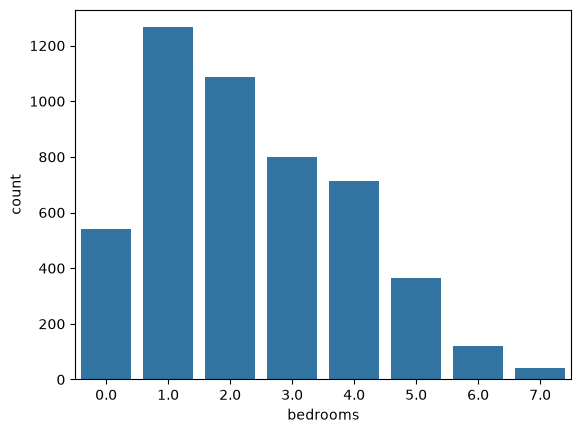

In [54]:
bedrooms = sns.countplot(x = df["bedrooms"])

In [55]:
df['bedrooms'].value_counts()

bedrooms
1.0    1265
2.0    1088
3.0     799
4.0     714
0.0     541
5.0     366
6.0     122
7.0      40
Name: count, dtype: int64

Most of the Data is of 1 bedrooms properties (1265), followed by 2 bedroom properties (1088) therefore both of these values account for almost **half** of the data in the dataset. Studio properties are 541 thus the model can also learn from the studio listings. We can also observe a decline from bedrooms 3 and above, 799 listings of 3 bedroom, 714 listings of 4 bedrooms and 366 listings of 5 bedroom properties. Large homes are **rare** with 6 bedroms 122 listings and 7 bedrooms 40 listings.

Since most data is on **small homes and apartments** thus model will predict them the **best**, however the predictions for **larger houses** with 6 to 7 bedrooms will be **less reliable** due to the lack of data the model was trained for those listings.

<Axes: >

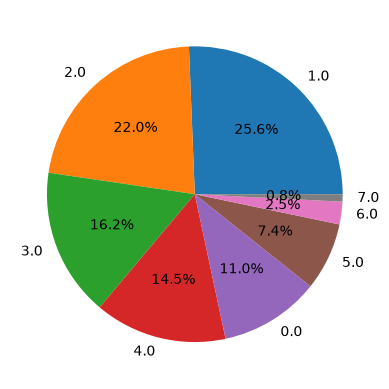

In [56]:
df['bedrooms'].value_counts().plot(kind = 'pie', autopct='%1.1f%%')

C:\Users\USER\AppData\Local\Temp\ipykernel_8452\4154995891.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  bathrooms.set_xticklabels([1,2,3,4,5,6,7])


[Text(0, 0, '1'),
 Text(1, 0, '2'),
 Text(2, 0, '3'),
 Text(3, 0, '4'),
 Text(4, 0, '5'),
 Text(5, 0, '6'),
 Text(6, 0, '7')]

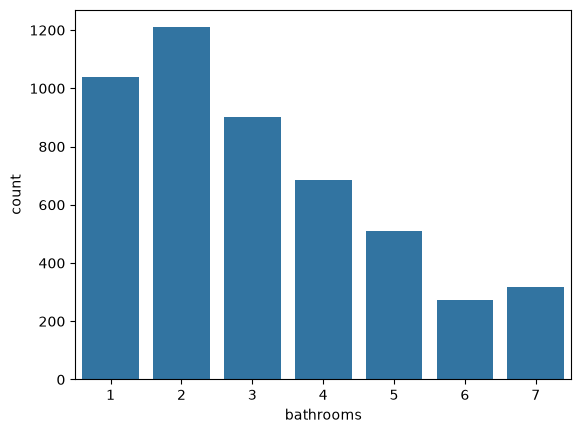

In [57]:
bathrooms = sns.countplot(x = df['bathrooms'])
bathrooms.set_xticklabels([1,2,3,4,5,6,7])

Most properties have 2 bathrooms, followed by 1 bathroom with only a few properties having 6 or more bathrooms, thus the model will be trained well on properties with fewer bathrooms like apartments or small homes, not on larger houses who's predictions will be less reliable due to few listings in our dataset

<Axes: >

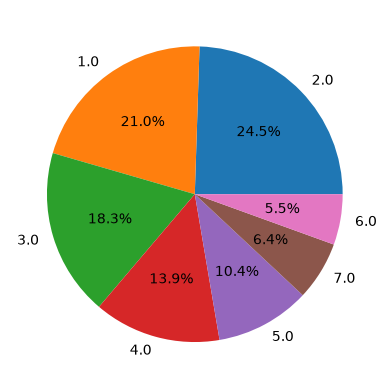

In [58]:
df['bathrooms'].value_counts().plot(kind = 'pie', autopct='%1.1f%%')

##### Categorical Features

Text(0.5, 1.0, 'Properties Furnishing')

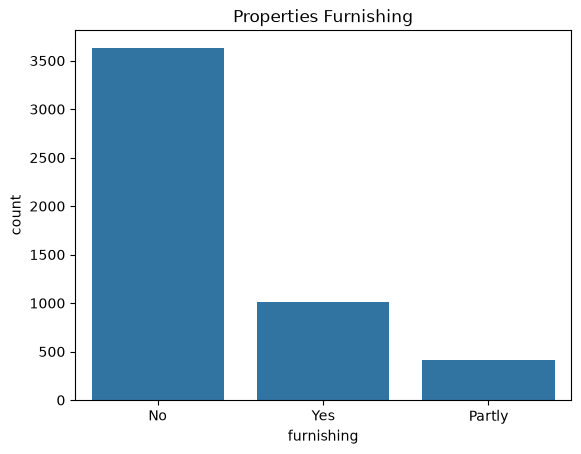

In [59]:
furnished = sns.countplot(x = df['furnishing'])
plt.title('Properties Furnishing')

<Axes: >

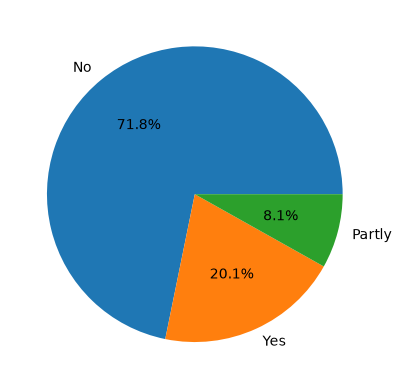

In [60]:
df['furnishing'].value_counts().plot(kind = 'pie', autopct='%1.1f%%')

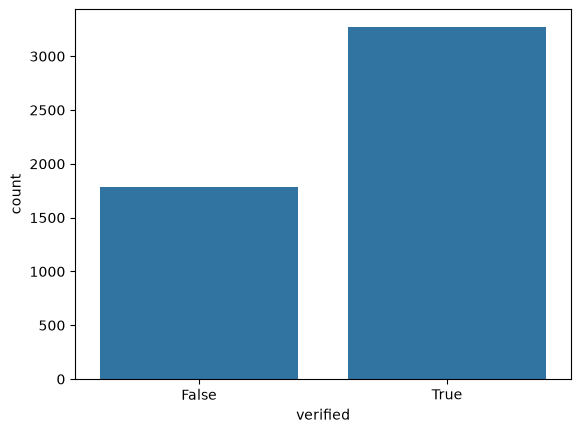

In [61]:
furnished = sns.countplot(x = df['verified'])

Text(0.5, 1.0, 'Listings per City')

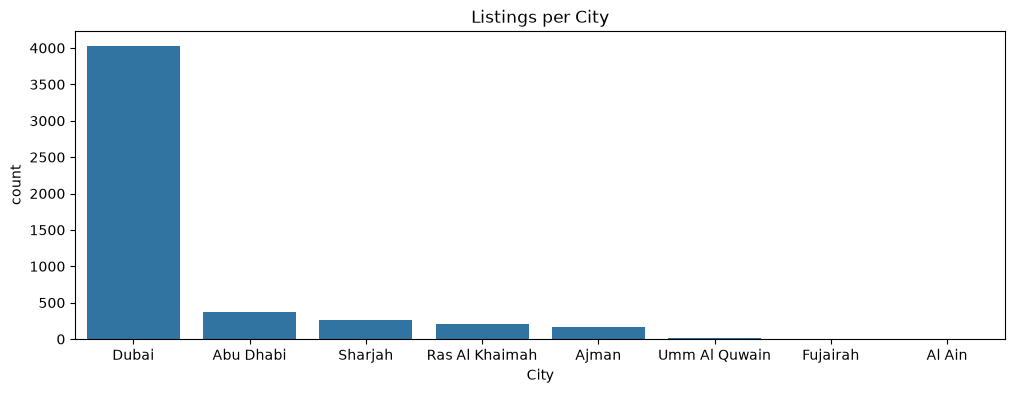

In [62]:
plt.figure(figsize = (12,4))
furnished = sns.countplot(x = df['City'], order = df['City'].value_counts().index)
plt.title('Listings per City')

In [63]:
df['City'].value_counts()

City
Dubai             4031
Abu Dhabi          370
Sharjah            267
Ras Al Khaimah     201
Ajman              170
Umm Al Quwain       11
Fujairah             4
Al Ain               4
Name: count, dtype: int64

In [64]:
df.columns 

Index(['title', 'bathrooms', 'bedrooms', 'price', 'verified', 'furnishing',
       'size_sqft', 'City', 'Community'],
      dtype='str')

Text(0.5, 1.0, 'Top 15 Communities by number of listings')

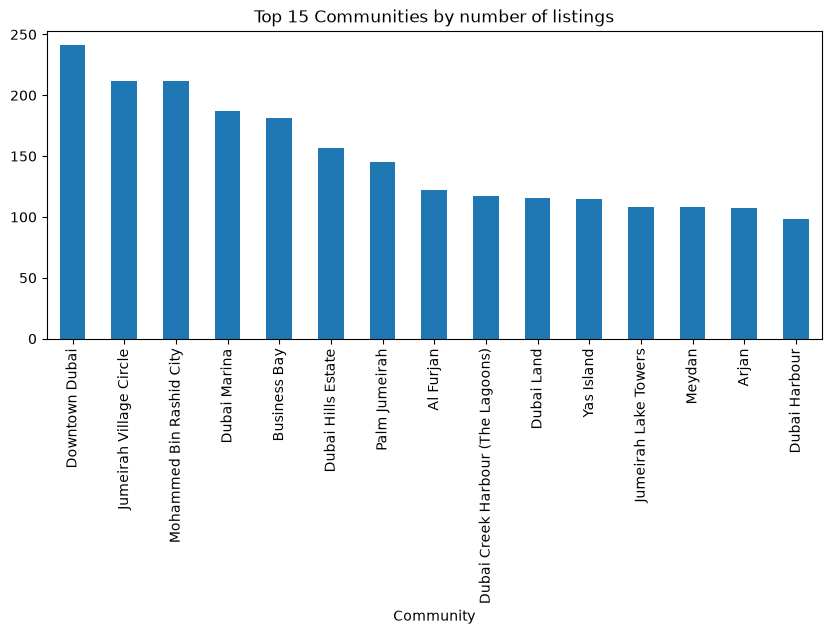

In [65]:
plt.figure(figsize = (10,4))
df["Community"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Communities by number of listings")

In [66]:
df["Community"].value_counts().head(15)

Community
Downtown Dubai                       241
Jumeirah Village Circle              212
Mohammed Bin Rashid City             212
Dubai Marina                         187
Business Bay                         181
Dubai Hills Estate                   157
Palm Jumeirah                        145
Al Furjan                            122
Dubai Creek Harbour (The Lagoons)    117
Dubai Land                           116
Yas Island                           115
Jumeirah Lake Towers                 108
Meydan                               108
Arjan                                107
Dubai Harbour                         98
Name: count, dtype: int64

The top communities that are found in the listing are from Dubai like Downtown Dubai, JVC (Jumairah Village Circle) and Mohammed Bin Rashid City 

In [67]:
df["Community"].nunique()

190

In [68]:
sum(df['Community'].value_counts() < 10)

98

##### Numeric Features

In [69]:
df['price'].describe()

count    5.058000e+03
mean     5.050924e+06
std      1.000928e+07
min      1.000000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.499375e+06
max      1.990000e+08
Name: price, dtype: float64

In [70]:
df.shape 

(5058, 9)

**Removing non-residential listings before EDA**

- These rows are removed prior to EDA since the model estimates the prices of residential properties (apartment, house, townhouse) and plots and buildings follow different pricing rules
- Their extreme sizes and prices would stretch the distributions, plots, and correlations, making the analysis of normal listings less clear.
- These values can't be filled since we would be inventing bedrooms and bathrooms for properties that have none.


In [71]:
df = df.dropna(subset = ['bedrooms']).reset_index(drop = True)

In [72]:
df.shape

(4935, 9)

In [73]:
df['price'].describe()

count    4.935000e+03
mean     4.937178e+06
std      9.715803e+06
min      1.000000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.401944e+06
max      1.990000e+08
Name: price, dtype: float64

In [74]:
df.isna().sum()

title         0
bathrooms     3
bedrooms      0
price         0
verified      0
furnishing    2
size_sqft     0
City          0
Community     0
dtype: int64

Text(0.5, 1.0, 'Price Histogram')

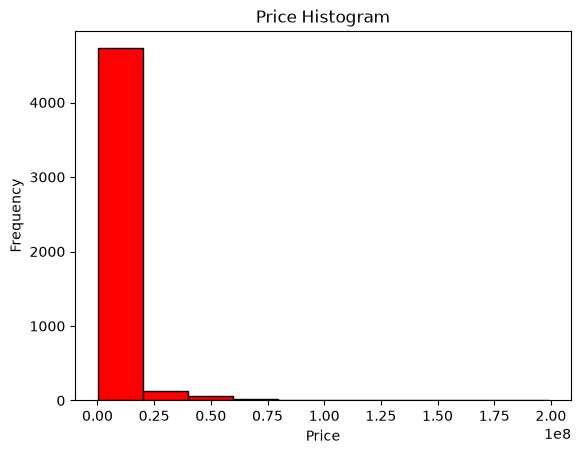

In [75]:
plt.hist(df['price'], bins = 10, color = 'red', edgecolor = 'Black')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Price Histogram")

Text(0.5, 0, 'log (Price + 1)')

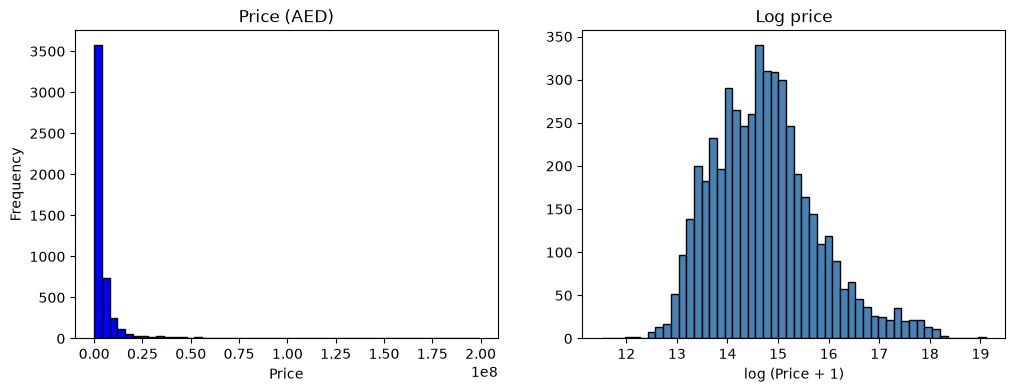

In [76]:
fig, axes = plt.subplots(1,2, figsize = (12,4))

axes[0].hist(df['price'], bins=50, color="blue", edgecolor="black")
axes[0].set_title("Price (AED)")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(df["price"]), bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log price")
axes[1].set_xlabel("log (Price + 1)")


The Price is **strongly right skewed** with most listings below 20M AED, while a few reach 200 million, the standard deviation (about 9.7M) is twice the mean (about 4.9M). After applying the 'np.log1p', we observe the distribution closer to a bell shape, centered around 2.4 million AED (the median is 2.35M), with a mild remaining right tail.

Therefore Training directly on this target would allow for the model to focus on the very few expensive listings errors avoiding fixing errors of listing below 20M that are mostly found in the dataset. Thus log transform ('np.log1p') will be applied to 'price' for modeling. 

In [77]:
df['price'].sort_values(ascending = False)

3542    199000000
1554    180000000
1687    144950000
2932    120000000
3198     90000000
          ...    
4581       210000
634        185000
4105       180000
2013       160000
834        100000
Name: price, Length: 4935, dtype: int64

In [78]:
df.sort_values("price", ascending=False)[["title", "City", "Community", "bedrooms", "size_sqft", "price"]].head(15)

,title,City,Community,bedrooms,size_sqft,price
3542,Ultra-Luxury | Duplex Penthouse | Branded,Dubai,Downtown Dubai,5.0,11196.0,199000000
1554,Ultra-Luxury Shell and Core Mansion |On Lagoon...,Dubai,Mohammed Bin Rashid City,7.0,34000.0,180000000
1687,Golf Facing Mansion | Vacant on Transfer,Dubai,Dubai Hills Estate,7.0,39139.0,144950000
2932,Freehold Independent Brand-New Ready Villa,Dubai,Al Wasl,7.0,20282.0,120000000
3198,Bespoke Luxury Villa with Lavish Interior Design,Dubai,Umm Al Sheif,5.0,15000.0,90000000
3156,Signature Penthouse Atlantis The Royal- 5 Bedr...,Dubai,Palm Jumeirah,5.0,6239.0,90000000
1317,Car Elevator | Exclusive | Billionaires Row,Dubai,Palm Jumeirah,6.0,14102.0,84000000
824,Vacant | Custom-Built | Modern Contemporary,Dubai,Palm Jumeirah,6.0,9700.0,77000000
2937,Exclusive Resale of an Impressive AVA Apartment,Dubai,Palm Jumeirah,4.0,7239.0,77000000
3735,Opulent Oasis | Exquisite Penthouse | Private ...,Dubai,Palm Jumeirah,5.0,9664.0,76500000


In [79]:
df.sort_values("size_sqft")[["title", "bedrooms", "size_sqft", "price",'Community']].head(10)

,title,bedrooms,size_sqft,price,Community
1002,Handover Sept | Iconic Tower | Easy ROI,0.0,82.0,850000,Dubai Marina
3117,Investor Deal | Boutique Apt | Serviced Amenities,0.0,257.0,850000,Jumeirah Village Circle
539,"ِAmazing offer,special location&amp;best price",0.0,290.0,329999,Aljada
2146,Handover Soon | Community View | Mid Floor,0.0,293.0,650000,Meydan
4017,Time 1 Dubailand | Vacant | Unfurnished,0.0,294.0,435000,Dubai Land
475,Chiller Free| Smart Home|Best Priced | Cozy St...,0.0,296.0,600000,Meydan
4078,High Floor | Ready Oct | Great Investment,0.0,296.0,597500,Meydan
3372,Ready to Move | Boulevard Facing View Unit,0.0,296.0,620000,Meydan
748,STUDIO | HIGH-FLOOR | MOTIVATED SELLER,0.0,297.0,800000,Barsha Heights (Tecom)
4230,Project completed |Handover Next Month,0.0,299.0,580000,Meydan


The smallest studio listings are between 250 to 300 sqft, which is realistic for the price. However, one of the listings has only 82 sqft for 850,000 AED in Dubai Marina, and the asking price is similar to that of properties above 200 sqft studios. 

This row would mislead the model, so it is removed by setting a minimum size of 150 sqft, thus removing only this one listing.  

In [80]:
df = df[df["size_sqft"] >= 150].reset_index(drop=True)
df

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square
...,...,...,...,...,...,...,...,...,...
4929,07 Layout | Handover Q2 2025 | Multiple Units ...,3.0,2.0,2345000,True,Partly,1268.0,Dubai,Mohammed Bin Rashid City
4930,Emaar | Waterfront Apartment | 10% DP | 5-Yr PP,2.0,1.0,3007888,False,No,854.0,Ras Al Khaimah,Al Marjan Island
4931,Upgraded | Spacious With Private Garden,5.0,4.0,4000000,True,No,3813.0,Dubai,Motor City
4932,"10 Series | Full Sea, Burj Khalifa View Exclusive",2.0,2.0,3800000,True,No,1300.0,Dubai,Dubai Creek Harbour (The Lagoons)


In [81]:
df["price_per_sqft"] = df["price"] / df["size_sqft"]

In [82]:
df.sort_values("price_per_sqft", ascending=False)[["title", "Community", "size_sqft", "price", "price_per_sqft"]].head(10)

,title,Community,size_sqft,price,price_per_sqft
3541,Ultra-Luxury | Duplex Penthouse | Branded,Downtown Dubai,11196.0,199000000,17774.205073
3794,Genuine Resale | Prime Location | Modern Living,Arjan,558.0,9499999,17025.087814
434,Exclusive | Luxurious Unit | Burj Khalifa View,Jumeirah,3169.0,50000000,15777.847902
2803,Skycourt 2 Bedroom Apartment | Duplex | Sea View,Palm Jumeirah,2992.0,45000000,15040.106952
4282,Private Pool and Terrace with Luxurious Interi...,Palm Jumeirah,3074.0,45000000,14638.906962
3155,Signature Penthouse Atlantis The Royal- 5 Bedr...,Palm Jumeirah,6239.0,90000000,14425.388684
1322,Fully Upgraded and Furnished | Luxury Apartment,Jumeirah,1937.0,24800000,12803.304078
2934,Exclusive Resale 3-Bedroom Designer Apartment,Jumeirah,2822.0,35000000,12402.551382
4595,Best Deal | Full Sea | Palm View |Royal Atlant...,Palm Jumeirah,3495.0,42500000,12160.228898
3894,Live In The World Iconic Project-Ocean View,Palm Jumeirah,1910.0,23000000,12041.884817


In [83]:
df[df['Community'] == 'Arjan']['price_per_sqft'].sort_values(ascending = False)

3794    17025.087814
4575     1887.777778
2972     1853.828306
4129     1760.705290
1314     1722.912966
            ...     
4259     1002.109705
3886      969.130869
809       941.883768
1889      936.902486
4592      853.242321
Name: price_per_sqft, Length: 107, dtype: float64

In [84]:
df.shape

(4934, 10)

When sorting by price per sqft, we can see that the highest values are really expensive properties in Downtown Dubai, Palm Jumeirah, and Jumeirah, which are kept. However, one listing stands out: a  558 sqft apartment in Arjan that is priced at 9499999 (17025.087814 price per sqft), roughly ten times the comparable units in the same Community. Most likely a Data entry error; thus, it was removed. 

In [85]:
df = df[~((df['Community'] == 'Arjan') & (df['price'] == 9499999))].reset_index(drop=True)

In [86]:
df.shape

(4933, 10)

In [87]:
df.sort_values("price_per_sqft")[["title", "Community", "size_sqft", "price", "price_per_sqft","City"]].head(10)

,title,Community,size_sqft,price,price_per_sqft,City
834,2 BHK | Resale | 100k Down Payment | 570k Remain,Al Bustan,1640.0,100000,60.975610,Ajman
579,Spacious Double Story 4 Bedroom Hall Villa,Al Riqqa,9000.0,950000,105.555556,Sharjah
2012,"PAY 160,000 AND OWN 1BHK FULL SEAVIEW, READY.",Al Bustan,1160.0,160000,137.931034,Ajman
4136,Modern Villa | 5 Master Room | AL Seih,Al Qusaidat,10000.0,1500000,150.000000,Ras Al Khaimah
2090,2BHK with Maids Room Near City For Sale,Yasmin Village,1400.0,230000,164.285714,Ras Al Khaimah
4679,Apartment for sale in Orient Tower with two rooms,Al Bustan,1483.0,250000,168.577208,Ajman
4579,1 Bhk For Sale In Paradise Lake Tower Closed K...,Emirates City,830.0,210000,253.012048,Ajman
4724,"For sale 6 BR Luxury Villa in Al Dhait ,Block 12",Al Dhait,10455.0,2675000,255.858441,Ras Al Khaimah
4070,For Sale Apartment On Concord Tower City View,Sheikh Maktoum Bin Rashid Street,2572.0,670000,260.497667,Ajman
4369,FOr Sale Corner Villa On Al Muwaihat3 NearMosque,Al Mowaihat,4682.0,1270000,271.251602,Ajman


In [88]:
raw = pd.read_csv("data/uae_real_estate_2024.csv")

In [89]:
pd.set_option('display.max_rows', None)
pd.set_option("display.max_colwidth", None)
raw[raw["title"].str.contains("100k Down Payment|PAY 160,000", case=False, na=False)]['description']

859                                                For sale in Orient Towers, 2 bedrooms, a hall, 2 bathrooms, a kitchen, a balcony and parking\nExcellent view\nTotal price 711 thousand dirhams\nPaid from the apartment value 140 thousand dirhams\nRemaining 571 thousand\nRequired for sale 100 thousand final\nThe apartment is empty\nApartment area 1650 feet\nMonthly installment 7000\n ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎ ‎

In [90]:
df = df [~((df["title"].str.contains("100k Down Payment|PAY 160,000", case=False)) & (df["Community"] == "Al Bustan"))].reset_index(drop = True)

The lowest prices per sqft are mostly in the cheaper northern emirates, as expected. Two apartments in Orient Towers, Al Bustan (Ajman) are an exception: their **price** shows only the down payment, while the ads state total prices of about 711,000 and 530,000 AED. Both rows are removed.

In [91]:
df = df.drop(["price_per_sqft"], axis = 1 )

In [92]:
df.head()

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
0,Great ROI I High Floor I Creek View,3.0,2.0,2500000,True,No,1323.0,Dubai,Business Bay
1,Full Sea View | Beach Life | Brand New Residence,3.0,2.0,7200000,True,Yes,1410.0,Dubai,Jumeirah Beach Residence
2,Green Belt | Corner Unit | Spacious Plot,3.0,4.0,3600000,True,No,2324.0,Dubai,Dubai Land
3,2BR+Study | Near Pool and Park | Private,3.0,2.0,2999999,True,No,1647.0,Dubai,The Springs
4,Vacant | Well Maintained | Area Expert,3.0,3.0,2449999,True,No,2105.0,Dubai,Town Square


C:\Users\USER\AppData\Local\Temp\ipykernel_8452\444587821.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price'])


<Axes: xlabel='price', ylabel='Density'>

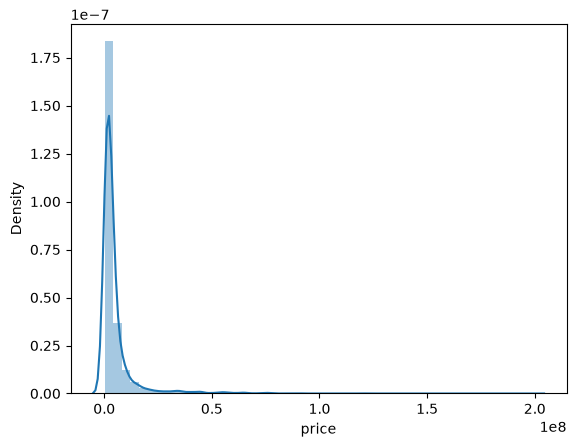

In [93]:
sns.distplot(df['price'])

C:\Users\USER\AppData\Local\Temp\ipykernel_8452\3123796009.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(np.log1p(df['price']))


<Axes: xlabel='price', ylabel='Density'>

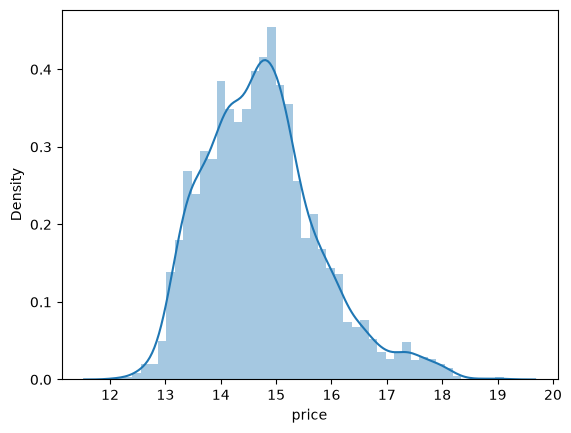

In [94]:
sns.distplot(np.log1p(df['price']))

<Axes: xlabel='price'>

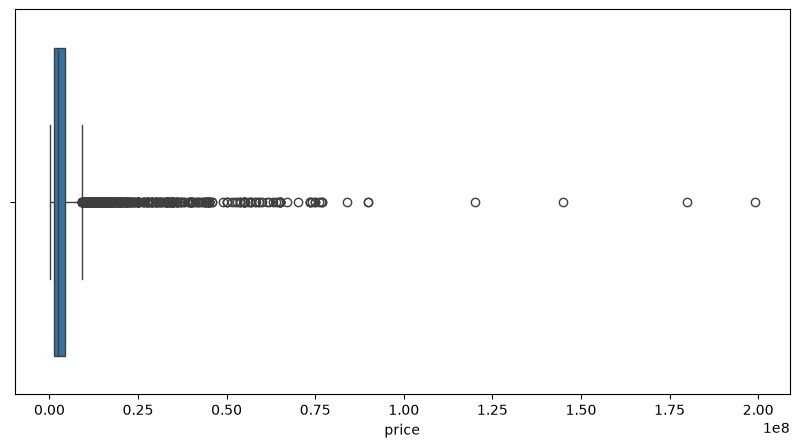

In [95]:
plt.figure(figsize = (10,5))
sns.boxplot(x = df['price']) 

In [96]:
df['price'].describe()

count    4.931000e+03
mean     4.939031e+06
std      9.718870e+06
min      1.800000e+05
25%      1.200000e+06
50%      2.350000e+06
75%      4.401944e+06
max      1.990000e+08
Name: price, dtype: float64

<Axes: xlabel='price'>

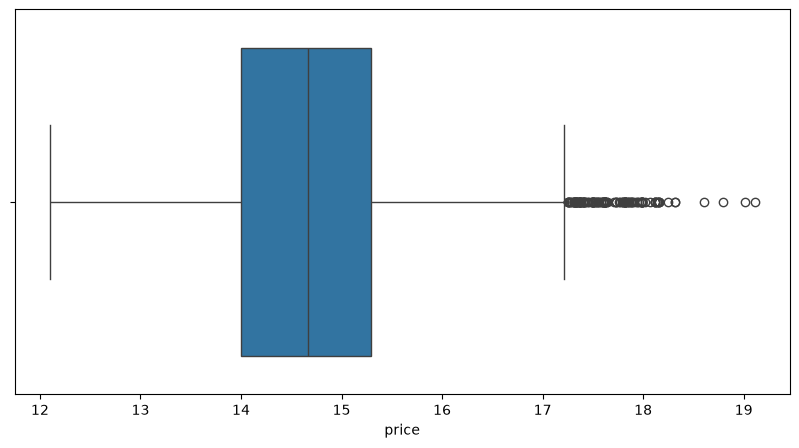

In [97]:
plt.figure(figsize = (10,5))
sns.boxplot(x = np.log1p(df['price'])) 

In [98]:
np.log1p(df['price']).describe()

count    4931.000000
mean       14.737612
std         1.037832
min        12.100718
25%        13.997833
50%        14.669926
75%        15.297557
max        19.108815
Name: price, dtype: float64

Observing the box plot we can see a completely right skewed distribution with several outliers when using the price feature. However once we apply the log transformation (np.log1p) we can observe the distribution becoming more symmetrically with a few outliers on the right tail.

Text(0.5, 1.0, 'Size (Sqft) Histogram')

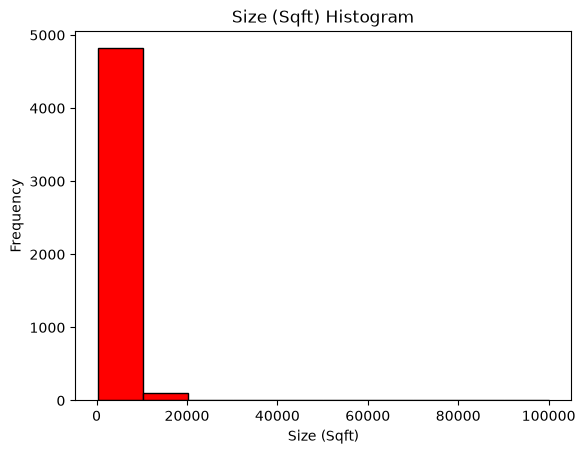

In [99]:
plt.hist(df['size_sqft'], bins = 10, color = 'red', edgecolor = 'Black')
plt.xlabel("Size (Sqft)")
plt.ylabel("Frequency")
plt.title("Size (Sqft) Histogram")

All properties are between 0 to 20,000 sqft in size 

In [100]:
df['size_sqft'].min(), df['size_sqft'].max()

(np.float64(257.0), np.float64(100000.0))

In [101]:
(df['size_sqft'] == 100000).sum()

np.int64(1)

In [102]:
(df['size_sqft'] > 20000).sum()

np.int64(9)

In [103]:
df['size_sqft'].skew(), np.log1p(df['size_sqft']).skew()

(np.float64(9.88392621316604), np.float64(0.5317493837325832))

We can observe that the log transform helps alot in terms of making it from heavely right skewed data to 0.53 skewness that is better normally distributed data, more symmetric 

In [104]:
df[df['size_sqft'] > 20000]

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
1036,Corner Plot I 5 Individual Villas I 5 bed +maid,6.0,5.0,35000000,True,No,27833.0,Dubai,Umm Suqeim
1237,Custom Build | 6 BDR | Vacant On Transfer,7.0,6.0,75000000,True,No,22184.0,Dubai,Emirates Hills
1552,Ultra-Luxury Shell and Core Mansion |On Lagoon|Full Vastu Compliant| District One,7.0,7.0,180000000,True,No,34000.0,Dubai,Mohammed Bin Rashid City
1685,Golf Facing Mansion | Vacant on Transfer,7.0,7.0,144950000,True,Yes,39139.0,Dubai,Dubai Hills Estate
2530,ROYAL PALACE | COMMERCIAL POTENTIAL READY,7.0,7.0,30000000,False,Yes,100000.0,Ras Al Khaimah,Al Dhait
2929,Freehold Independent Brand-New Ready Villa,7.0,7.0,120000000,False,Yes,20282.0,Dubai,Al Wasl
3144,"Vacant! Emirates Hills Signature Villa | 100% Lake Facing | 20,486 Sqft Plot Size",5.0,6.0,57000000,True,Partly,20486.0,Dubai,Emirates Hills
3796,Exquisite and Spacious Luxury Villa in Umm Suqeim,7.0,7.0,65000000,True,Yes,40000.0,Dubai,Umm Suqeim
4044,Full Sea View | Vacant | Private Beach Access,7.0,6.0,42999888,True,No,71419.0,Abu Dhabi,Nurai Island


In [105]:
df['size_sqft'].describe()

count      4931.000000
mean       2363.542892
std        3239.804290
min         257.000000
25%         796.500000
50%        1383.000000
75%        2690.000000
max      100000.000000
Name: size_sqft, dtype: float64

Text(0.5, 0, 'log (Size + 1)')

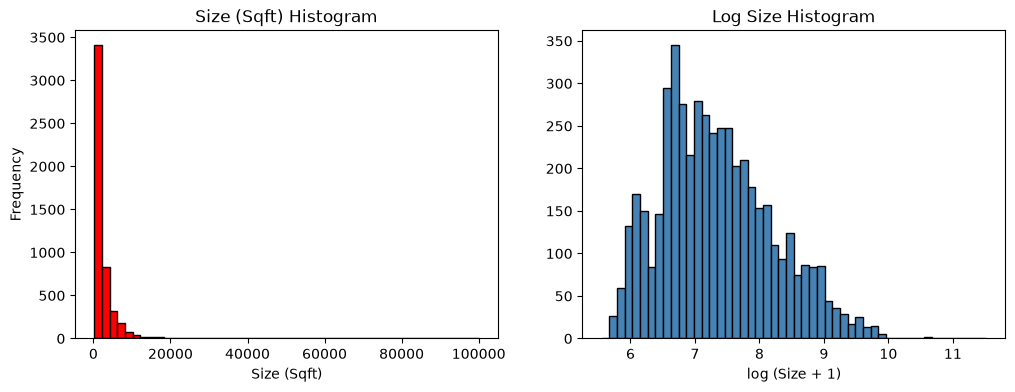

In [106]:
fig, axes = plt.subplots(1,2, figsize = (12,4))

axes[0].hist(df['size_sqft'], bins=50, color="red", edgecolor="black")
axes[0].set_title("Size (Sqft) Histogram")
axes[0].set_xlabel("Size (Sqft)")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(df["size_sqft"]), bins=50, color="steelblue", edgecolor="black")
axes[1].set_title("Log Size Histogram")
axes[1].set_xlabel("log (Size + 1)")

The raw size_sqft` distribution is strongly right-skewed.Almost all properties fall below 5000 sqft, while only a few are exceptions that are 100,000 sqft, thus most data is in the first bin.

After applying **np.log1p** we can observe the distribution becomes more bell curved and symmetrical. 

Thus the transformed feature is therefore much better suited for linear and distance based models. 

C:\Users\USER\AppData\Local\Temp\ipykernel_8452\189261462.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['size_sqft'])


<Axes: xlabel='size_sqft', ylabel='Density'>

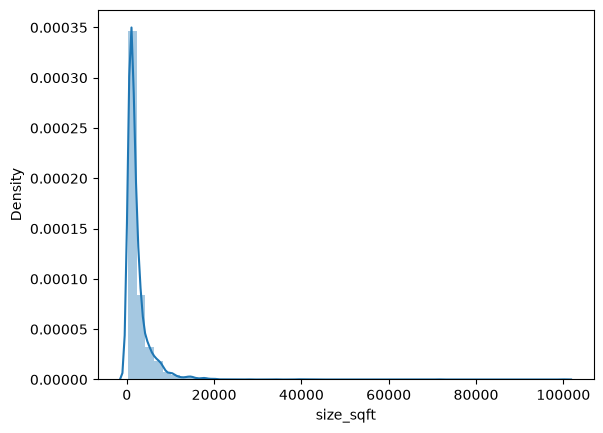

In [107]:
sns.distplot(df['size_sqft'])

C:\Users\USER\AppData\Local\Temp\ipykernel_8452\3210601703.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(np.log1p (df['size_sqft']))


<Axes: xlabel='size_sqft', ylabel='Density'>

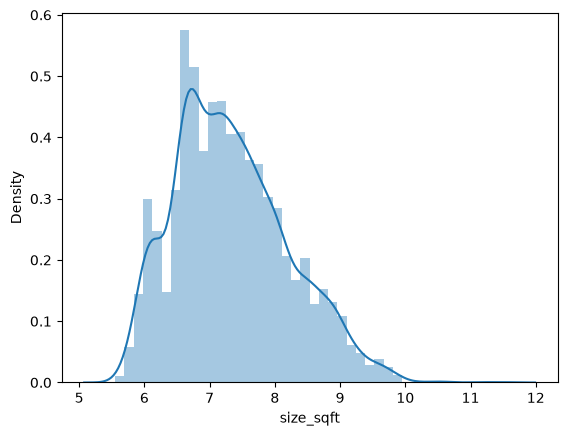

In [108]:
sns.distplot(np.log1p (df['size_sqft']))

<Axes: xlabel='size_sqft'>

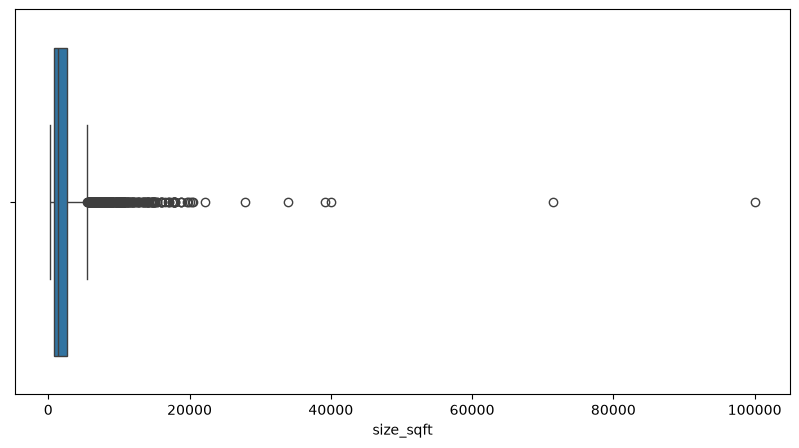

In [109]:
plt.figure(figsize = (10,5))
sns.boxplot(x = df['size_sqft']) 

<Axes: xlabel='size_sqft'>

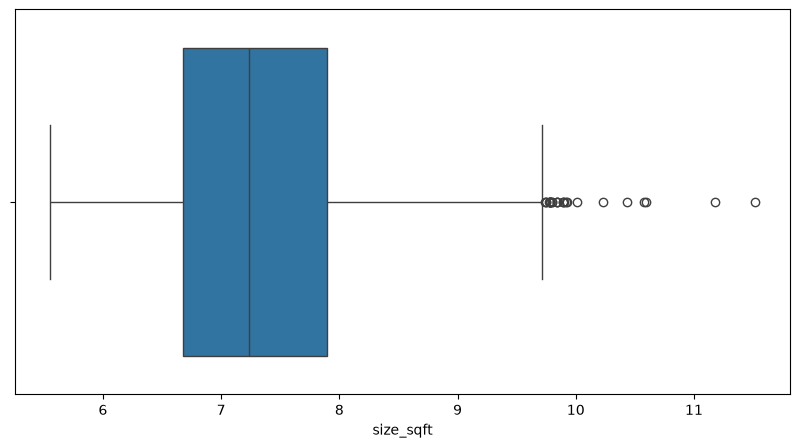

In [110]:
plt.figure(figsize = (10,5))
sns.boxplot(x =np.log1p( df['size_sqft'])) 


In [111]:
np.log1p( df['size_sqft']).median(), np.log1p( df['size_sqft']).max(), np.log1p( df['size_sqft']).quantile([0.25,0.75])

(np.float64(7.232733136177615),
 np.float64(11.51293546492023),
 0.25    6.681482
 0.75    7.897668
 Name: size_sqft, dtype: float64)

In the box-and-whisker plot, the raw size_sqft is compressed on the left side, and the maximum value stretches to 100,000 sqft.  

After np.log1p, we can see that the box plot is more centered, with the median near 7.2, IQR from about 6.7 to 7, and only a few extreme sizes thus reducing the influence of such sizes without removing them. 

#### Bivariate Analysis & Multivariate Analysis

##### Scattered Plot

<Axes: xlabel='size_sqft', ylabel='price'>

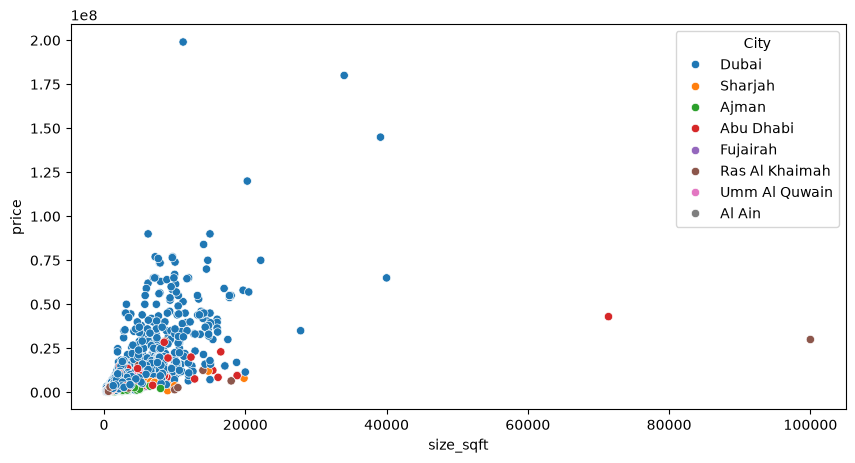

In [112]:
plt.figure(figsize = (10,5))
sns.scatterplot(x = df['size_sqft'] , y = df['price'], hue = df['City'])

We can observe a strong postively linear corrrelation, since size_sqft increases the price also tends to increase (0.61 correlation). We can also observe for same size_sqft listings some prices are higher or lower, therefore location can also play a huge role in influencing the properties price. 



Text(0, 0.5, 'log(1 + price)')

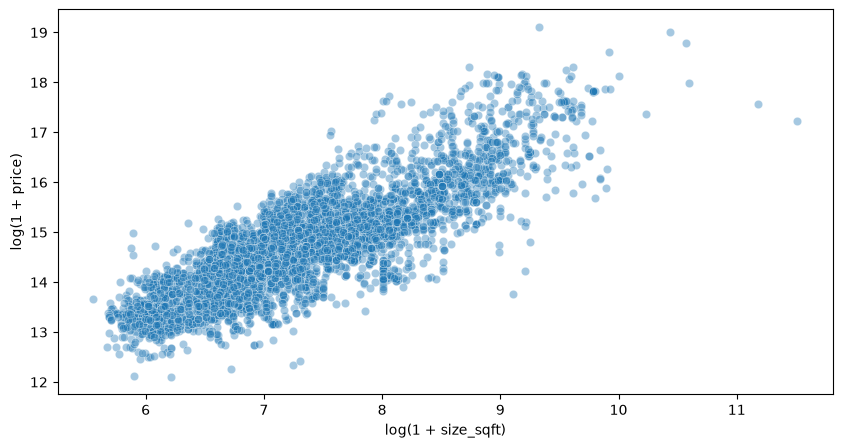

In [113]:
plt.figure(figsize = (10,5))
sns.scatterplot(x=np.log1p(df["size_sqft"]), y=np.log1p(df["price"]), alpha=0.4)
plt.xlabel("log(1 + size_sqft)")
plt.ylabel("log(1 + price)")


In the log-log scale, we can observe a linear relationship between 'size_sqft' and 'price'. The wide spread of data for each size suggests that other features like location also influence price too.This supports log transforming 'price'.

Text(0, 0.5, 'log(1 + price)')

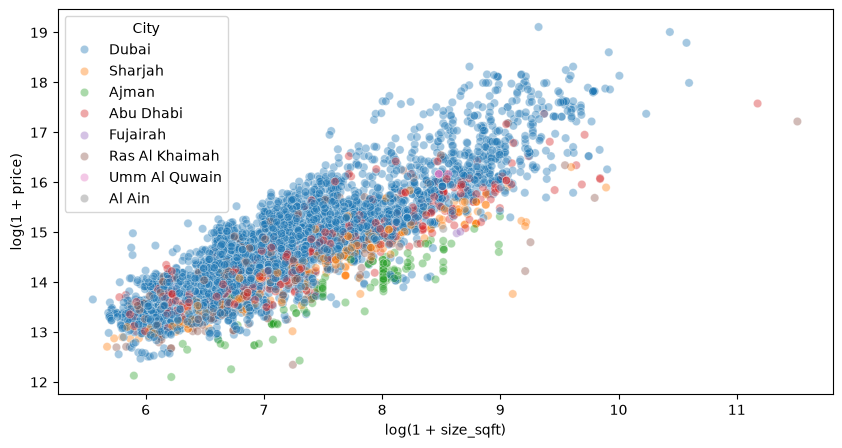

In [114]:
plt.figure(figsize = (10,5))
sns.scatterplot(x=np.log1p(df["size_sqft"]), y=np.log1p(df["price"]), hue = df['City'], alpha=0.4)
plt.xlabel("log(1 + size_sqft)")
plt.ylabel("log(1 + price)")


##### Bar Plot

Text(0.5, 1.0, 'Median price in the 15 most common communities')

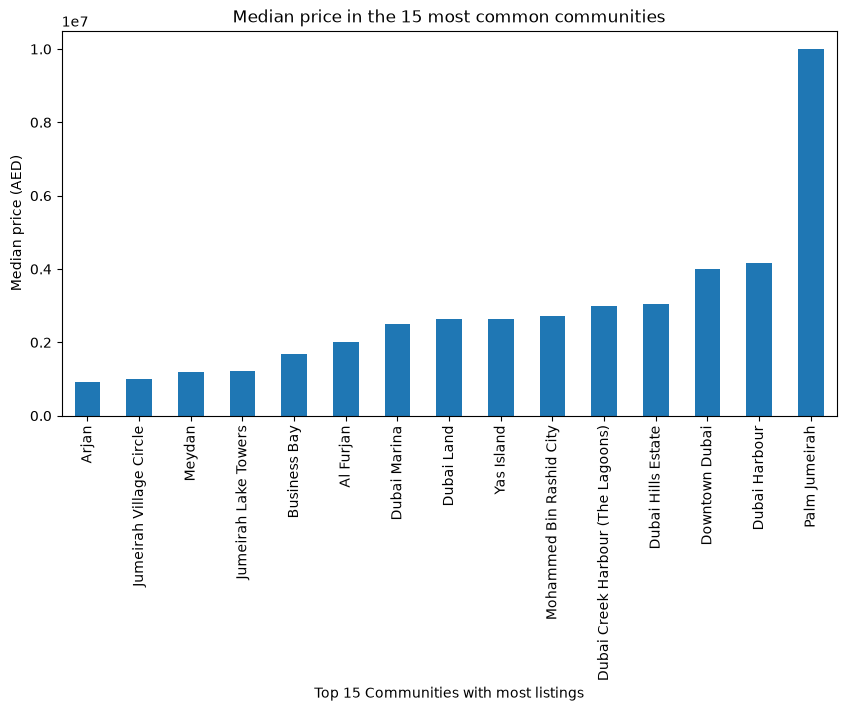

In [115]:
top_community = df["Community"].value_counts().head(15).index 

median_price_communities = df[df["Community"].isin(top_community)].groupby('Community')['price'].median().sort_values()


plt.figure(figsize=(10, 5))
median_price_communities.plot(kind="bar")
plt.ylabel("Median price (AED)")
plt.xlabel("Top 15 Communities with most listings")
plt.title("Median price in the 15 most common communities")




We can observe that median prices also vary strongly based on community. Palm Jumairah is the highest of the cheapest communities (Arjan, JVC and Meydan) by 10 times the value of them (10 M AED). The gap is also influenced by the property types, however location also matters, thus **community** will be used as a **feature**.

##### Box Plot

Text(0, 0.5, 'log(Price + 1)')

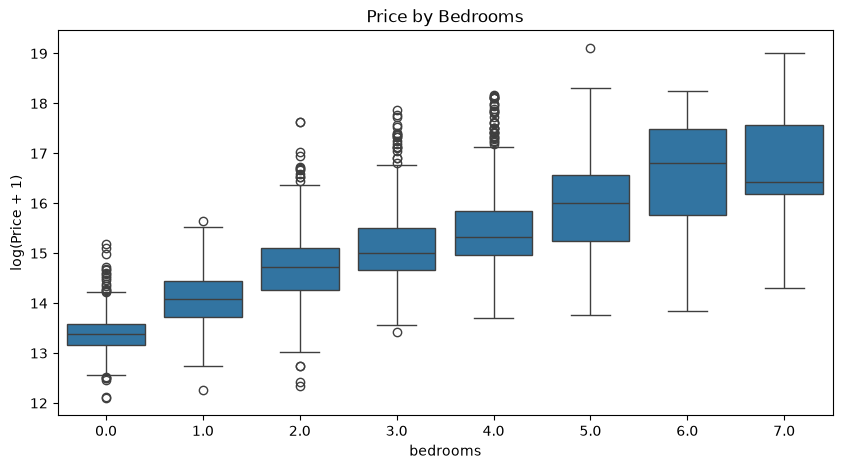

In [116]:
plt.figure(figsize=(10, 5))
sns.boxplot(x = df['bedrooms'], y = np.log1p(df['price']))
plt.title('Price by Bedrooms')
plt.ylabel('log(Price + 1)')

Text(0, 0.5, 'log(Price + 1)')

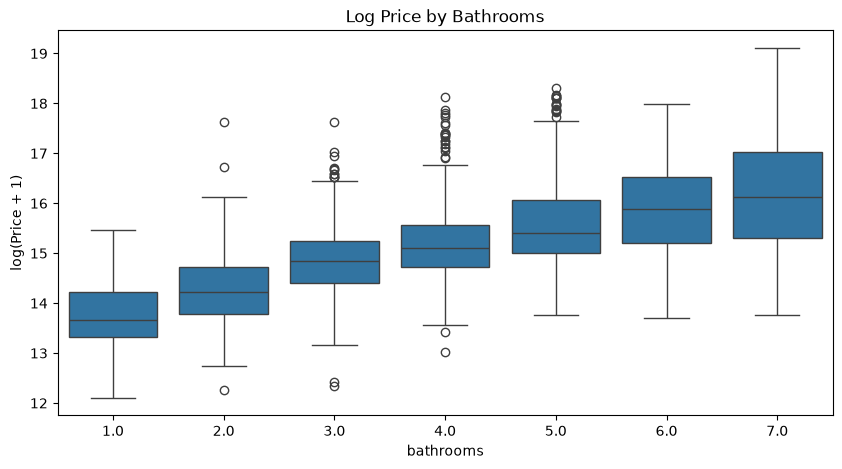

In [117]:
plt.figure(figsize=(10, 5))
sns.boxplot(x = df['bathrooms'], y = np.log1p(df['price']))
plt.title('Log Price by Bathrooms')
plt.ylabel('log(Price + 1)')

**Observation**: As the number of bathrooms or bedrooms increase so does the log Price 

Text(0, 0.5, 'log(Price + 1)')

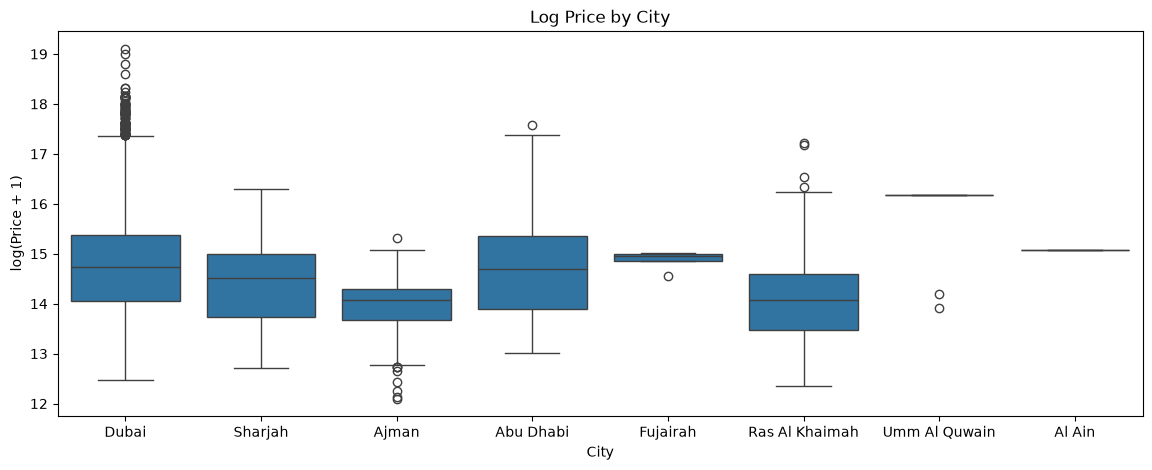

In [118]:
plt.figure(figsize=(14, 5))
sns.boxplot(x = df['City'], y = np.log1p(df['price']))
plt.title('Log Price by City')
plt.ylabel('log(Price + 1)')

Prices are shown as log(price + 1). With Dubai and Abu Dhabi having similar medians about 14.7 (about 2.4M AED).However dubai has the most outliers up till 19.1.Sharjah has a lower median about 14.5, while Ajman has the lowest 14.1 ( about 1.3M AED). Due to Few listings Fujairah , Umm Al Quwain and Al Ain has lower listings thus they can't be reliably compared to other cities 

In [119]:
df.groupby('City')['price'].agg(['count', 'median', 'mean']).sort_values('median',ascending = False)

,count,median,mean
City,,,
Umm Al Quwain,9,10500000.0,8.450651e+06
Al Ain,1,3500000.0,3.500000e+06
Fujairah,4,3149500.0,2.924500e+06
Dubai,3980,2500000.0,5.454773e+06
Abu Dhabi,355,2400000.0,3.853637e+06
Sharjah,247,2000000.0,2.385796e+06
Ajman,136,1300000.0,1.315362e+06
Ras Al Khaimah,199,1300000.0,2.094936e+06


We can observe most listings (3,980 of 4,931, about 81%) are from dubai and since mean is greater than the median we can say that it contains several outliers that have expensive prices . Abu Dhabi contains (355 listings) and Sharjah (247 listings) with medians of 2.4 million and 2 million AED. 

 Ajman and Ras Al Khaimah both have a median of 1.3M, but Ras Al Khaimah's mean is higher, suggesting a wider spread.

Text(0, 0.5, 'log(Price + 1)')

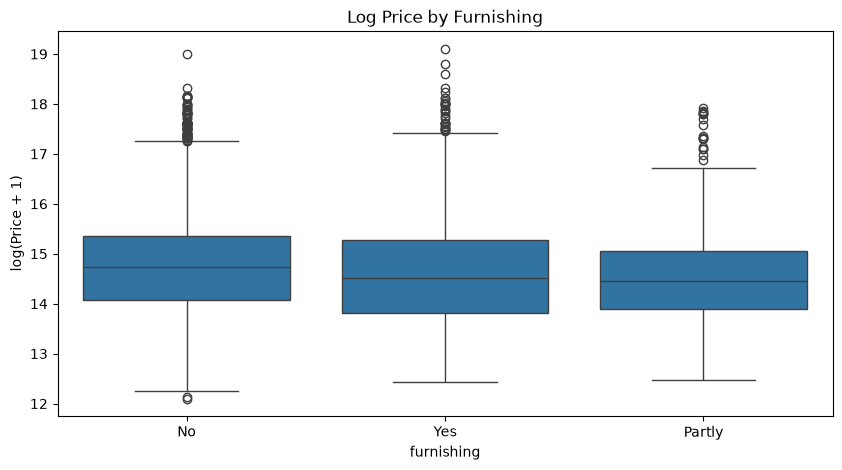

In [120]:
plt.figure(figsize=(10, 5))
sns.boxplot(x = df['furnishing'], y = np.log1p(df['price']))
plt.title('Log Price by Furnishing')
plt.ylabel('log(Price + 1)')

The median log prices for unfurnished (No), Furnished (Yes) and partly furnished listings are very close, going from 14.5 to 14.7. With unfurnished having the highest median. 

Furnishing doesn't seem to shift pricing. Most of the spread is due to either location or size, which the other features were able to detect.  

Unfurnished groups also contains the most outliers since it has mostly luxery properties.


##### Heat Map

<Axes: >

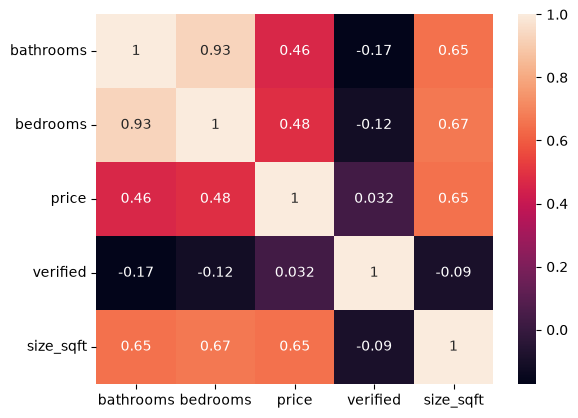

In [121]:
sns.heatmap(df.corr(numeric_only = True), annot = True)

We can observe a **strong positive correlation** between size_sqft and price (0.65), followed by bedrooms with the correlation of (0.48) and bathrooms (0.46).  

We can also observe that bedrooms and bathrooms are highly correlated with each other (0.93) thus we can use one rather than both.  









In [122]:
df.pivot_table(aggfunc = 'median', values = 'price', index = 'City', columns = 'bedrooms')

bedrooms,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0
City,,,,,,,,
Abu Dhabi,890000.0,970000.0,1917000.0,2725000.0,5999995.0,8174999.5,8500000.0,9500000.0
Ajman,248000.0,507254.0,532053.5,1290000.0,1375000.0,1450000.0,1600000.0,2560000.0
Al Ain,NaN,NaN,NaN,NaN,NaN,3500000.0,NaN,NaN
Dubai,650000.0,1390000.0,2799999.5,3800000.0,4650000.0,11700000.0,28500000.0,22000000.0
Fujairah,NaN,NaN,2099000.0,3250000.0,3099000.0,NaN,NaN,NaN
Ras Al Khaimah,575000.0,954422.0,1550000.0,2524250.0,6500000.0,12500000.0,2675000.0,18250000.0
Sharjah,473000.0,769000.0,1495000.0,2049000.0,3130012.5,3887000.0,6940000.0,10028500.0
Umm Al Quwain,NaN,1106863.0,1449000.0,NaN,10500000.0,NaN,NaN,NaN


Median prices rises with bedrooms in every city, but the size of the increase in price differs based on the different emirates.  
The median prices for a 4 bedroom property in Dubai is 4.6M, and 5 bedroom is 11.7M, while 4 bedroom property in Abu Dhabi has roughly the median price of 6M AED and 5 bedroom is 8.17M AED.

Therefore city and bedrooms interact favoring tree based models.


## EDA Summary

- **price** feature is heavly right skewed, therefore the model should be trained on **log1p(price)**
- **size_sqft** is the strongest numeric predictor (correlation of 0.65), followed by **bedrooms** and then **bathrooms**, which both overlap strongly (0.93) thus one feature in both of them will be used for training.
- Location matters a lot: in different communities, median prices differ a lot, and the effect of bedrooms differ by city.
- **Verified** has almost no relationship with **price** (0.032)
- Since there are few listings in smaller emirates, thus predictions there will be unreliable

## Checking Outliers 

In [123]:
df.shape
df.isna().sum()

title         0
bathrooms     3
bedrooms      0
price         0
verified      0
furnishing    2
size_sqft     0
City          0
Community     0
dtype: int64

In [124]:
num_features = list(df.dtypes[(df.dtypes != 'str') & (df.dtypes != 'bool')].index)
num = df[num_features]
Q1 = num.quantile(0.25)
Q3 = num.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = (num < lower) | (num > upper)

outliers.sum()

bathrooms      0
bedrooms       0
price        528
size_sqft    462
dtype: int64

- There are 462 outliers of size_sqft column and 528 outliers of price, that account for about 10% of the data in each column. While **bedroom** and **bathrooms** have none.
- Since in the EDA we observed that both of these columns (size_sqft and price) are right skewed thus this could be genuinely large, expensive properties rather than, not errors, thus are **kept**. 



In [125]:
log_num = np.log1p(df[["price", "size_sqft"]])
Q1 = log_num.quantile(0.25)
Q3 = log_num.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = (log_num < lower) | (log_num > upper)

outliers.sum()


price        136
size_sqft     27
dtype: int64

In [126]:
(log_num < lower).sum(), (log_num > upper).sum()

(price        0
 size_sqft    0
 dtype: int64,
 price        136
 size_sqft     27
 dtype: int64)

- On the log scale, the IQR ruling flags 136 outlier listings in **price** column and 27 outliers in **size_sqft**, all at the high end.
- They are mostly luxery properties and large villa, so they are genuinely kept 

## Checking and Dealing with Duplicates  

In [127]:
df.duplicated().sum()

np.int64(6)

In [128]:
dup = df[df.duplicated(keep = False)].sort_values(['title','price'])
dup[['title', 'City','Community', 'size_sqft', 'price']]

,title,City,Community,size_sqft,price
894,4 Bedrooms + Maid l Vacant l Multiple options,Dubai,Jumeirah Village Circle,2627.0,2850000
1233,4 Bedrooms + Maid l Vacant l Multiple options,Dubai,Jumeirah Village Circle,2627.0,2850000
1048,5 Beds | Large Plot | Type A | Penthouse,Dubai,Tilal Al Ghaf,8156.0,15500000
1085,5 Beds | Large Plot | Type A | Penthouse,Dubai,Tilal Al Ghaf,8156.0,15500000
4650,A villa with a modern design for all nationalities,Ajman,Al Amerah,3100.0,1760000
4654,A villa with a modern design for all nationalities,Ajman,Al Amerah,3100.0,1760000
2513,Avena | Lush Green Resort Lifestyle | Sky Suite,Dubai,The Valley,3750.0,4350000
2516,Avena | Lush Green Resort Lifestyle | Sky Suite,Dubai,The Valley,3750.0,4350000
2624,Golf Community | Custom Build G+1 Modern Villa,Dubai,Jumeirah Golf Estates,7158.0,18000000
2876,Golf Community | Custom Build G+1 Modern Villa,Dubai,Jumeirah Golf Estates,7158.0,18000000


In [129]:
df = df.drop_duplicates().reset_index(drop = True)

In [130]:
df.shape

(4925, 9)

**6 listings** appear twice in the dataset with identical values in each columns ('title', 'City','Community', 'size_sqft', 'price') thus are considered as reposted ads. The duplicates are removed so they don't end up in both training and testing data. 

In [131]:
df.sample(5)

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
1557,Genuine Resale | Burj Khalifa View | Best Priced,3.0,3.0,6200000,True,No,1801.0,Dubai,Downtown Dubai
441,Own an apartment in Ajman at the Dubai entrance,2.0,2.0,519000,False,No,1200.0,Ajman,Al Alia
642,Stunning Villa | Private Pool | Maid Room | Vacant,3.0,2.0,4250000,False,No,3059.0,Dubai,The Springs
3634,Chiller Free | 2BR with Private Terraced Apartment,3.0,2.0,3850000,False,No,1946.0,Dubai,Old Town
429,Spacious Villa with a Great Design and Price,7.0,5.0,1990000,False,No,4350.0,Ajman,Al Alia


## Cleaning the Dataset

In [132]:
df.Community.nunique()

177

In [133]:
counts = df['Community'].value_counts()
counts 

Community
Downtown Dubai                       241
Mohammed Bin Rashid City             212
Jumeirah Village Circle              211
Dubai Marina                         186
Business Bay                         181
Dubai Hills Estate                   157
Palm Jumeirah                        144
Al Furjan                            121
Dubai Creek Harbour (The Lagoons)    117
Dubai Land                           115
Yas Island                           111
Jumeirah Lake Towers                 108
Meydan                               107
Arjan                                106
Dubai Harbour                         98
DAMAC Hills                           95
Dubai South (Dubai World Central)     87
Damac Hills 2                         78
Damac Lagoons                         77
Dubai Sports City                     76
Town Square                           73
Tilal Al Ghaf                         72
Al Reem Island                        69
Dubai Investment Park (DIP)           69
The Va

In [134]:
(counts < 10).sum()

np.int64(91)

In [135]:
counts[counts < 10].sum()

np.int64(321)

There are 91 communities that have listings less than 10 times in the data set out of 177 communities and overall they account for 321 listings in the entire dataset out of the 4925 total listings (6.5 % of the total data)

In [136]:
df = df[~ df["title"].str.contains("Residential Freehold land plot", case=False, na=False)]

Removed another row that contained a plot listing rather than a residential property listing 

In [137]:
df.shape

(4924, 9)

In [138]:
df['Community'].value_counts() 

Community
Downtown Dubai                       241
Mohammed Bin Rashid City             212
Jumeirah Village Circle              211
Dubai Marina                         186
Business Bay                         181
Dubai Hills Estate                   157
Palm Jumeirah                        144
Al Furjan                            121
Dubai Creek Harbour (The Lagoons)    117
Dubai Land                           114
Yas Island                           111
Jumeirah Lake Towers                 108
Meydan                               107
Arjan                                106
Dubai Harbour                         98
DAMAC Hills                           95
Dubai South (Dubai World Central)     87
Damac Hills 2                         78
Damac Lagoons                         77
Dubai Sports City                     76
Town Square                           73
Tilal Al Ghaf                         72
Al Reem Island                        69
Dubai Investment Park (DIP)           69
The Va

In [139]:
df[(df['City'] == 'Ras Al Khaimah') & (df['title'].str.contains('Royal Palace', case = False))]

,title,bathrooms,bedrooms,price,verified,furnishing,size_sqft,City,Community
2527,ROYAL PALACE | COMMERCIAL POTENTIAL READY,7.0,7.0,30000000,False,Yes,100000.0,Ras Al Khaimah,Al Dhait


In [140]:
print(df.loc[2527, ['title', 'price', 'size_sqft', 'City']])

title        ROYAL PALACE | COMMERCIAL POTENTIAL READY
price                                         30000000
size_sqft                                     100000.0
City                                    Ras Al Khaimah
Name: 2527, dtype: object


In [141]:
df = df.drop(index=2527)

In [142]:
print(2527 in df.index)

False


In [143]:
df = df.reset_index(drop=True)

Dropped listing 2527 (Ras Al Khaimah) 'Royal Palace' , 100,000 sqft , 30M AED. It is a commercial scale palace not a residential home.

In [144]:
raw[raw['title'].str.contains('Royal Palace', case = False)]

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description
2582,ROYAL PALACE | COMMERCIAL POTENTIAL READY,"Al Dhait North, Al Dhait, Ras Al Khaimah",7+,7+,2024-07-30T12:30:35Z,Residential for Sale,30000000,False,sell,100000 sqft,YES,"Welcome to an extraordinary palace, previously owned by a royal family,\nand a true masterpiece of design by an Iranian artist who dedicated 15 years to its creation.\n\nThis magnificent estate is adorned with historical objects, furniture, and artworks from around the globe, including exquisite pieces from Syria, Morocco, India, and China. You&#39;ll marvel at the hand-painted walls and mosaics that add a touch of elegance to every corner.\n\nThe façade of the palace is adorned with a very special white marble that originates from the Kaaba in Mecca. This exquisite marble not only protects the palace from external heat but also imbues it with profound religious significance.\n\nThe palace sits on a vast 200,000 sq ft plot on a prominent hill and boasts 20 distinct bedrooms, each one unlike the other, 20 luxurious bathrooms, and 8 grand halls. With a sprawling 100,000 square feet of built-up area, there&#39;s ample space to explore and enjoy. Additional features include a serene prayer hall, a well-equipped office, and a spacious kitchen.\n\nAfter being abandoned for almost 30 years, the palace has been completely restored by the current owner over the past year. Its history is filled with intrigue, as many world-famous politicians and celebrities have tried to purchase this palace, but it was never available for sale.\n\nThis palace not only holds immense historical and cultural value but also presents a wealth of commercial opportunities. Plans are already in place to transform it into a successful venture, whether it be a luxury hotel, a fine dining restaurant with a rooftop bar or theme park attraction with thrill rides.\n\nAdding to its allure, the palace is shrouded in legend, rumored to be haunted, which only enhances its charm. It&#39;s currently the number one famous palace in the Middle East and ranks as the fifth most renowned palace worldwide.\n\nContact us today for valuation reports and more information on this incredible investment opportunity."


In [145]:
print(df.loc[3797, ['title', 'bedrooms', 'bathrooms', 'price', 'size_sqft']])
print(df['bedrooms'].value_counts().sort_index())

title        Exclusive. Deluxe Villa. Single Row. Private Pool
bedrooms                                                   5.0
bathrooms                                                  7.0
price                                                  9990000
size_sqft                                               8238.0
Name: 3797, dtype: object
bedrooms
0.0     540
1.0    1262
2.0    1087
3.0     799
4.0     710
5.0     365
6.0     121
7.0      39
Name: count, dtype: int64


In [146]:
df.shape

(4923, 9)

In [147]:
df.isna().sum()

title         0
bathrooms     3
bedrooms      0
price         0
verified      0
furnishing    2
size_sqft     0
City          0
Community     0
dtype: int64

## Property Price Prediction Modelling

In [148]:
from sklearn.model_selection import train_test_split

y = np.log1p(df['price'])
X = df.drop(columns = ['price'])

X_full_train, X_test, y_full_train, y_test = train_test_split( X, y, test_size=0.2, random_state=1)

X_train, X_val, y_train, y_val = train_test_split(X_full_train, y_full_train, test_size=0.25, random_state=1)

In [149]:
print(X_train.shape[0], X_val.shape[0], X_test.shape[0])

2953 985 985


In [150]:
X_train.dtypes

title             str
bathrooms     float64
bedrooms      float64
verified         bool
furnishing        str
size_sqft     float64
City              str
Community         str
dtype: object

In [151]:
for d in (X_train, X_val, X_test):
    d['log_size_sqft'] = np.log1p(d['size_sqft'])

In [152]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline

num_cols = ['bedrooms', 'log_size_sqft']
cat_cols = ['City', 'Community', 'furnishing', 'verified']

preprocessing_lr = ColumnTransformer ([
    ('num', SimpleImputer(strategy = 'median'), num_cols), 
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown = 'ignore', min_frequency=10, drop='first'),), cat_cols),
])

X_train_t = preprocessing_lr.fit_transform(X_train[num_cols + cat_cols])
X_val_t = preprocessing_lr.transform(X_val[num_cols + cat_cols])
X_test_t = preprocessing_lr.transform(X_test[num_cols + cat_cols])

print(X_train_t.shape, X_val_t.shape, X_test_t.shape)


(2953, 74) (985, 74) (985, 74)


C:\Users\USER\Documents\Dubai Property Price Estimator (DataTalks ML Zoomcamp)\Dubai-Property-Price-Estimator\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\USER\Documents\Dubai Property Price Estimator (DataTalks ML Zoomcamp)\Dubai-Property-Price-Estimator\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


1) The split is performed first. Medians, categories and rare-community groups are learned from the training set only, then applied to validation and test

**Preprocessing**:
1) Numeric columns have missing values filled with the training median
2) Categorical columns have missing values filled with the mode value. Then one-hot encoding with communities less than 10 listings in the training are placed in an 'infrequent' column; communities that are not seen in the training dataset have become all zeros; drop='first' drops the first unnecessary column needed for linear regression to avoid multicollinarity
3) Title is not used as a feature

Validation and test contain City or Community values that are not seen in the training, thus are encoded as all zeros ,thus predictions for such values are unreliable

## Model Evaluation

In [153]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def Calculate_metrics(model, description, X_val , y_val):
    pred = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    mae = mean_absolute_error(np.expm1(y_val), np.expm1(pred))
    r2 = r2_score(y_val, pred)
    print(f"{description} | RMSE(log): {rmse:.3f} | MAE(AED): {mae:,.0f} | R2: {r2:.3f}")
    return rmse, mae, r2

1) **RMSE** in log scale to compare the multiple models (Lower is better) and measured on log price since the model was trained on that scale
2) **MAE** the avg size of miss in dirhams, after converting back with np.expm1.
3) **R2** Compares the effectiveness of the models prediction against just using the mean for prediction of a house price

In [154]:
def train_val_gap(model, name):
    tr_pred = model.predict(X_train_t)
    va_pred = model.predict(X_val_t)
    tr_mae = mean_absolute_error(np.expm1(y_train), np.expm1(tr_pred))
    va_mae = mean_absolute_error(np.expm1(y_val), np.expm1(va_pred))
    tr_r2 = r2_score(y_train, tr_pred)
    va_r2 = r2_score(y_val, va_pred)
    print(f"{name:<12} Train MAE: {tr_mae:,.0f}  Val MAE: {va_mae:,.0f}  Train R2: {tr_r2:.3f}  Val R2: {va_r2:.3f}")

## Linear Regression

In [155]:
from sklearn.linear_model import LinearRegression 

In [156]:
lr_model = LinearRegression()

In [157]:
lr_model.fit(X_train_t, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](74,)","[ 0.11, 0.79,-1.06,..., 0.03, 0.07,-0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.533
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,74


In [158]:
Calculate_metrics(lr_model, "Linear Regression Validation",X_val_t, y_val)

Linear Regression Validation | RMSE(log): 0.317 | MAE(AED): 1,367,300 | R2: 0.909


(np.float64(0.31659408754480306), 1367300.2280098659, 0.9086365961370483)

- R2 of 0.909 means that the variation in price is 90.9% explained by the features
- RMSE is 0.317 (log scale) that is x 1.37 above or ÷ 1.37 below the true price
- MAE shows that there is a typical miss of about 1.37M AED, possibly due to the luxery listings

In [159]:
train_val_gap(lr_model, "Linear")


Linear       Train MAE: 1,447,288  Val MAE: 1,367,300  Train R2: 0.917  Val R2: 0.909


Linear regression shows no signs of overfitting:
- Validation is better than training slightly
- The R2 are nearly identical

We can observe that both scores are high on R2 and both MAE's are also high in AED, thus the model is underfitting rather than overfitting.